# Practical Session: The Transformer Architecture

Welcome to the full Transformer practical. Today we will dissect the architecture that revolutionized modern Deep Learning.

**Part 1 — Instructor Demos**
We will mathematically prove the recurrent bottleneck, examine how sub-word tokenization works, visualize Positional Encodings, demystify the Multi-Head "illusion," and walk through the exact masking operations.

**Part 2 — The DIY Transformer**
You will assemble a complete Encoder-Decoder Seq2Seq Transformer **from scratch** using PyTorch, and train it on a character-level task: translating human-readable dates into ISO format.


## Part 1: Instructor Demos

### Demo 1 — The Recurrent Bottleneck
Why did we abandon the RNN? Look at the execution time of a **sequential loop** versus a **highly parallelized matrix multiplication**.


In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# --- 1. The Recurrent Bottleneck ---------------------------------------
# A vanilla RNN cell must process one timestep at a time because h_t
# depends on h_{t-1}: this sequential dependency prevents parallelization.
batch_size, seq_len, hidden_dim = 64, 500, 256
dummy_input = torch.randn(batch_size, seq_len, hidden_dim).to(device)
W_hh = torch.randn(hidden_dim, hidden_dim).to(device)
W_xh = torch.randn(hidden_dim, hidden_dim).to(device)

print("Running sequential RNN loop...")
start_time = time.time()
h_t = torch.zeros(batch_size, hidden_dim).to(device)
for t in range(seq_len):
    x_t = dummy_input[:, t, :]  # [batch_size, hidden_dim]
    h_t = torch.tanh(x_t @ W_xh.T + h_t @ W_hh.T)
rnn_time = time.time() - start_time
print(f"Sequential RNN time: {rnn_time:.4f}s")

# --- 2. The Parallel Attention Equivalent (Matrix Multiplication) ------
# Attention computes all pairwise interactions in a single batched matmul,
# with no dependency between timesteps -> fully parallelizable on GPU.
Q = torch.randn(batch_size, seq_len, hidden_dim).to(device)
K = torch.randn(batch_size, seq_len, hidden_dim).to(device)

print("Running parallel attention (matrix multiplication)...")
start_time = time.time()
# [B, T, D] @ [B, D, T] -> [B, T, T]
attention_scores = torch.bmm(Q, K.transpose(1, 2)) / math.sqrt(hidden_dim)
attn_time = time.time() - start_time
print(f"Parallel attention time: {attn_time:.4f}s")
print(f"Speedup factor: {rnn_time / attn_time:.2f}x")


Device: cuda
Running sequential RNN loop...
Sequential RNN time: 0.4061s
Running parallel attention (matrix multiplication)...
Parallel attention time: 0.0287s
Speedup factor: 14.14x


### Demo 2 — Sub-Word Tokenization (Byte-Pair Encoding)
Word-level tokenization misses new words. Character-level is too long. **BPE** finds the perfect middle ground.


In [2]:
# Run this pip install if you haven't:
# !pip install -q transformers
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

word_1 = "embeddings"
word_2 = "TransformersAreCool"

print(f"Original: {word_1}")
print(f"Tokens:   {tokenizer.tokenize(word_1)}")
print("-" * 40)
print(f"Original: {word_2}")
print(f"Tokens:   {tokenizer.tokenize(word_2)}")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Original: embeddings
Tokens:   ['em', '##bed', '##ding', '##s']
----------------------------------------
Original: TransformersAreCool
Tokens:   ['transformers', '##are', '##co', '##ol']


### Demo 3 — Positional Encoding (Injecting Geometry)
Without recurrence, the Transformer treats a sequence as a "bag of words." We need to inject a sense of order.

We use sine and cosine functions because they act like a **continuous, high-dimensional binary counter**:
* The early dimensions (like the right-most bits in binary) oscillate very quickly.
* The later dimensions (like the left-most bits) oscillate very slowly.

**Why sines and cosines?**
Because of trigonometric identities, moving forward a fixed distance in a sequence is mathematically equivalent to simply *rotating* the positional vector:

$$PE_{(pos+k)} = R_k \cdot PE_{(pos)}$$

This means the Attention mechanism can easily calculate the **relative distance** between two tokens just by taking their dot product! We will visualize this below.


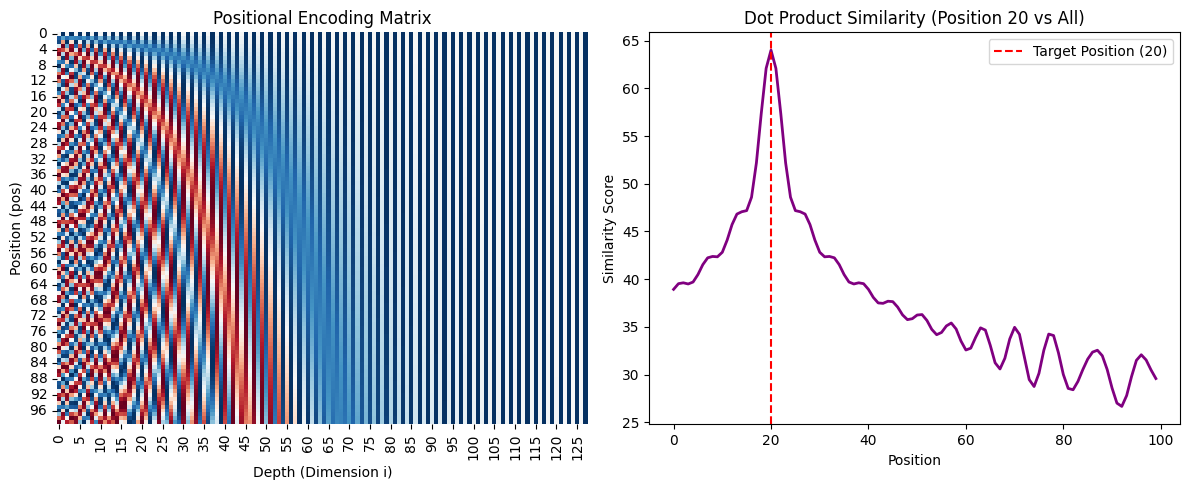

The dot product decays smoothly as we move away from position 20 -
this lets attention inherently sense which tokens are nearby.


In [3]:
def get_positional_encoding(seq_len: int, d_model: int) -> torch.Tensor:
    """Compute sinusoidal positional encodings.

    Args:
        seq_len: Number of positions to encode.
        d_model: Embedding dimensionality.

    Returns:
        Tensor of shape [seq_len, d_model].
    """
    pe = torch.zeros(seq_len, d_model)
    # Column vector of sequence positions: [[0], [1], [2], ...]
    position = torch.arange(0, seq_len, dtype=torch.float).unsqueeze(1)

    # Frequency divisor: 10000^(2i / d_model), computed in log-space for stability.
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model))

    # Sine on even indices, cosine on odd indices.
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


d_model = 128
seq_len = 100
pe_matrix = get_positional_encoding(seq_len, d_model)

# --- Visualization 1: The heatmap ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.heatmap(pe_matrix.numpy(), cmap="RdBu", cbar=False)
plt.title("Positional Encoding Matrix")
plt.xlabel("Depth (Dimension i)")
plt.ylabel("Position (pos)")

# --- Visualization 2: Proving relative distance ---
# Extract the positional vector for token #20.
pos_20_vector = pe_matrix[20]

# Dot product (similarity) of position 20 with every other position -
# this is what the Attention mechanism "feels" when comparing positions.
similarities = torch.matmul(pe_matrix, pos_20_vector)

plt.subplot(1, 2, 2)
plt.plot(similarities.numpy(), color="purple", linewidth=2)
plt.axvline(x=20, color="red", linestyle="--", label="Target Position (20)")
plt.title("Dot Product Similarity (Position 20 vs All)")
plt.xlabel("Position")
plt.ylabel("Similarity Score")
plt.legend()

plt.tight_layout()
plt.show()

print("The dot product decays smoothly as we move away from position 20 -")
print("this lets attention inherently sense which tokens are nearby.")


### Demo 4 — Multi-Head Splitting & The Causal Mask
Multi-head attention does **not** mean multiple layers running in a loop. It is a mathematical illusion created by *reshaping* the tensor before performing the dot product:

$$\text{shape: } [B, T, D] \;\longrightarrow\; [B, H, T, D/H]$$

The **causal mask** ensures the model cannot look into the future during autoregressive generation, by setting all "future" attention scores to $-\infty$ before the softmax.


In [4]:
# --- Multi-Head Reshaping ---
batch_size, seq_len, d_model = 2, 5, 512
num_heads = 8
d_k = d_model // num_heads

print("--- Multi-Head Illusion ---")
Q_raw = torch.randn(batch_size, seq_len, d_model)
print(f"Original Q shape:    {Q_raw.shape}")

# Split d_model into (num_heads, d_k), then swap seq_len and num_heads so
# each head is treated as an independent "batch" for the matmul.
Q_heads = Q_raw.view(batch_size, seq_len, num_heads, d_k).transpose(1, 2)
print(f"Multi-Head Q shape:  {Q_heads.shape}  -> (batch, heads, seq_len, d_k)")

# --- Causal Masking ---
print("\n--- The Causal Mask ---")
raw_scores = torch.ones(5, 5)  # Dummy attention scores

# Lower-triangular mask: 1s on and below the diagonal, 0s above.
mask = torch.tril(torch.ones(5, 5))
print("Binary mask:\n", mask)

# Replace disallowed ("future") positions with -inf before the softmax.
masked_scores = raw_scores.masked_fill(mask == 0, float("-inf"))
print("\nMasked scores (-inf added):\n", masked_scores)

# Softmax maps -inf to exactly 0.0, so future positions get zero weight.
attention_weights = F.softmax(masked_scores, dim=-1)
print("\nFinal attention weights:\n", attention_weights)


--- Multi-Head Illusion ---
Original Q shape:    torch.Size([2, 5, 512])
Multi-Head Q shape:  torch.Size([2, 8, 5, 64])  -> (batch, heads, seq_len, d_k)

--- The Causal Mask ---
Binary mask:
 tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])

Masked scores (-inf added):
 tensor([[1., -inf, -inf, -inf, -inf],
        [1., 1., -inf, -inf, -inf],
        [1., 1., 1., -inf, -inf],
        [1., 1., 1., 1., -inf],
        [1., 1., 1., 1., 1.]])

Final attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


---
## Part 2: The DIY Transformer

**The Task:** Build the architecture diagram from the 2017 paper *"Attention Is All You Need"* exactly as designed.

**The Dataset:** A generated character-level dataset translating human dates to ISO format (e.g., `August 3, 2026` $\rightarrow$ `2026-08-03`).

We have provided:
* The **data generator** and vocabulary.
* The **Embedding + Positional Encoding** logic.
* The **training loop**.

Your job is to construct the **Encoder**, the **Decoder**, and assemble the main `Seq2SeqTransformer` class.


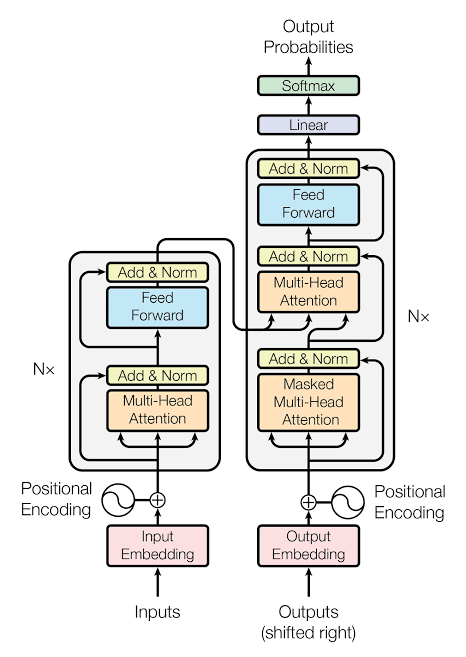

In [5]:
# Run this cell to set up the data and helper classes.
import random
import datetime

# --- 1. Generate the character-level date-translation dataset ---------
def generate_date_pairs(num_samples: int = 10000) -> list[tuple[str, str]]:
    """Generate (human-readable, ISO) date string pairs.

    Args:
        num_samples: Number of random dates to generate.

    Returns:
        List of (human_date, iso_date) string tuples, e.g.
        ("August 3, 2026", "2026-08-03").
    """
    months = [
        "January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December",
    ]
    pairs = []
    for _ in range(num_samples):
        dt = datetime.date(random.randint(1950, 2050), random.randint(1, 12), random.randint(1, 28))
        human = f"{months[dt.month - 1]} {dt.day}, {dt.year}"
        iso = dt.strftime("%Y-%m-%d")
        pairs.append((human, iso))
    return pairs


pairs = generate_date_pairs(10000)
chars = list(set("".join([p[0] + p[1] for p in pairs])))
vocab = ["<PAD>", "<SOS>", "<EOS>"] + sorted(chars)
char2idx = {c: i for i, c in enumerate(vocab)}
idx2char = {i: c for i, c in enumerate(vocab)}


def encode_str(s: str, max_len: int = 20, add_sos: bool = False, add_eos: bool = False) -> torch.Tensor:
    """Encode a string into a fixed-length, padded tensor of vocab indices."""
    seq = []
    if add_sos:
        seq.append(char2idx["<SOS>"])
    seq.extend([char2idx[c] for c in s])
    if add_eos:
        seq.append(char2idx["<EOS>"])
    pad_len = max_len - len(seq)
    seq.extend([char2idx["<PAD>"]] * pad_len)
    return torch.tensor(seq[:max_len], dtype=torch.long)


class DateDataset(torch.utils.data.Dataset):
    """Wraps (human, ISO) date pairs as encoded (src, tgt_in, tgt_out) tensors."""

    def __init__(self, pairs: list[tuple[str, str]]):
        self.pairs = pairs

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, i: int):
        src = encode_str(self.pairs[i][0], max_len=20)
        tgt_in = encode_str(self.pairs[i][1], max_len=15, add_sos=True)
        tgt_out = encode_str(self.pairs[i][1], max_len=15, add_eos=True)
        return src, tgt_in, tgt_out


dataloader = torch.utils.data.DataLoader(DateDataset(pairs), batch_size=64, shuffle=True)


# --- 2. Token + learned positional embeddings --------------------------
class TokenAndPositionEmbedding(nn.Module):
    """Sums a token embedding with a learned positional embedding."""

    def __init__(self, vocab_size: int, d_model: int, max_len: int = 100):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=char2idx["<PAD>"])
        self.pos_emb = nn.Embedding(max_len, d_model)  # Simplified learned positional encoding.

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Token ids, shape [batch_size, seq_len].

        Returns:
            Embedded tensor, shape [batch_size, seq_len, d_model].
        """
        positions = torch.arange(0, x.size(1), device=x.device).unsqueeze(0)
        return self.token_emb(x) + self.pos_emb(positions)


### Task 1: The Encoder Block
Wire up a single Encoder layer.

**Your Focus:** The `__init__` method is already built for you. Your job is to orchestrate the `forward` pass.

* **Data Flow:**
$$\text{Input} \;\rightarrow\; \text{Self-Attention} \;\rightarrow\; \text{Add \& Norm} \;\rightarrow\; \text{Feed Forward} \;\rightarrow\; \text{Add \& Norm}$$

* **Self-Attention:** $\text{Attention}(Q, K, V) = \text{softmax}\left(\dfrac{QK^\top}{\sqrt{d_k}}\right)V$, with $Q = K = V = \text{src}$.
* **Add & Norm:** $\text{LayerNorm}(x + \text{Sublayer}(x))$ — the residual connection stabilizes gradients through deep stacks.


In [6]:
class EncoderBlock(nn.Module):
    """A single Transformer Encoder layer: Self-Attention + Feed-Forward,
    each wrapped in a residual connection followed by LayerNorm."""

    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        # 1. We provide the initialized components.
        self.self_attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, src: torch.Tensor, src_key_padding_mask: torch.Tensor = None) -> torch.Tensor:
        """
        Args:
            src: Input embeddings, shape [batch_size, seq_len, d_model].
            src_key_padding_mask: Boolean mask, shape [batch_size, seq_len],
                True at <PAD> positions (ignored by attention).

        Returns:
            Encoded representation, shape [batch_size, seq_len, d_model].
        """
        # 1. Self-Attention: Query, Key, and Value all come from 'src'.
        attn_output, _ = self.self_attn(
            src, src, src, key_padding_mask=src_key_padding_mask
        )

        # --- SHAPE CHECK ---
        assert attn_output.shape == src.shape, f"Expected {src.shape}, got {attn_output.shape}"

        # 2. Add & Norm: residual connection stabilizes gradients, then normalize.
        out1 = self.norm1(src + attn_output)

        # 3. Position-wise Feed-Forward Network.
        ff_output = self.ffn(out1)

        # 4. Add & Norm again.
        out2 = self.norm2(out1 + ff_output)

        return out2


### Task 2: The Decoder Block
Wire up a single Decoder layer. This is where the magic happens.

**Masking Cheat Sheet:**
PyTorch's `nn.MultiheadAttention` takes very specific mask arguments — do not mix them up!

| Argument | Shape | Purpose |
|---|---|---|
| `attn_mask` | `[tgt_len, tgt_len]` | 2D **causal** matrix (lower-triangular). Prevents the decoder from looking into the future. Pass `tgt_mask` here during **self-attention**. |
| `key_padding_mask` | `[batch_size, seq_len]` | 1D **boolean** mask (`True` where `<PAD>` tokens are). Ignores empty padding slots. Pass `tgt_key_padding_mask` during **self-attention**, and `memory_key_padding_mask` during **cross-attention**. |

* **Data Flow:**
$$\text{tgt} \rightarrow \text{Masked Self-Attn} \rightarrow \text{Add \& Norm} \rightarrow \text{Cross-Attn (with memory)} \rightarrow \text{Add \& Norm} \rightarrow \text{Feed Forward} \rightarrow \text{Add \& Norm}$$


In [7]:
class DecoderBlock(nn.Module):
    """A single Transformer Decoder layer: Masked Self-Attention, Cross-Attention
    over the Encoder's memory, and a Feed-Forward network — each wrapped in a
    residual connection followed by LayerNorm."""

    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

        # Populated on every forward() call so downstream code (e.g. the bonus
        # cross-attention heatmap) can inspect the alignment without changing
        # this method's return signature.
        self.last_cross_attn_weights = None

    def forward(
        self,
        tgt: torch.Tensor,
        memory: torch.Tensor,
        tgt_mask: torch.Tensor = None,
        tgt_key_padding_mask: torch.Tensor = None,
        memory_key_padding_mask: torch.Tensor = None,
    ) -> torch.Tensor:
        """
        Args:
            tgt: Decoder input embeddings, shape [batch_size, tgt_len, d_model].
            memory: Encoder output ("the information bridge"),
                shape [batch_size, src_len, d_model].
            tgt_mask: Causal mask, shape [tgt_len, tgt_len] (-inf above diagonal).
            tgt_key_padding_mask: Boolean mask, shape [batch_size, tgt_len].
            memory_key_padding_mask: Boolean mask, shape [batch_size, src_len].

        Returns:
            Decoded representation, shape [batch_size, tgt_len, d_model].
        """
        # 1. Masked Self-Attention: Query, Key, Value all come from 'tgt'.
        # attn_mask enforces causality; key_padding_mask ignores <PAD> tokens.
        self_attn_output, _ = self.self_attn(
            tgt, tgt, tgt,
            attn_mask=tgt_mask,
            key_padding_mask=tgt_key_padding_mask,
        )

        # --- SHAPE CHECK ---
        assert self_attn_output.shape == tgt.shape, (
            f"Self-attn mismatch: Expected {tgt.shape}, got {self_attn_output.shape}"
        )

        # 2. Add & Norm.
        tgt2 = self.norm1(tgt + self_attn_output)

        # 3. Cross-Attention (the Information Bridge): Query from the decoder,
        # Key/Value from the encoder's 'memory'.
        cross_attn_output, cross_attn_weights = self.cross_attn(
            tgt2, memory, memory,
            key_padding_mask=memory_key_padding_mask,
        )
        self.last_cross_attn_weights = cross_attn_weights  # [batch, tgt_len, src_len]

        # --- SHAPE CHECK ---
        assert cross_attn_output.shape == tgt2.shape, (
            f"Cross-attn mismatch: Expected {tgt2.shape}, got {cross_attn_output.shape}"
        )

        # 4. Add & Norm.
        tgt3 = self.norm2(tgt2 + cross_attn_output)

        # 5. Feed-Forward, then Add & Norm.
        ff_output = self.ffn(tgt3)
        out = self.norm3(tgt3 + ff_output)

        return out


### Task 3: Assemble the Machine
Now map the initialized components together in the master module to complete the architecture:

$$\text{logits} = \text{Linear}\Big(\text{Decoder}\big(\text{tgt\_emb},\ \text{Encoder}(\text{src\_emb})\big)\Big)$$


In [8]:
class Seq2SeqTransformer(nn.Module):
    """Full Encoder-Decoder Seq2Seq Transformer, assembled from stacked
    EncoderBlock / DecoderBlock layers."""

    def __init__(
        self,
        vocab_size: int,
        d_model: int = 128,
        num_heads: int = 4,
        num_layers: int = 2,
        d_ff: int = 256,
    ):
        super().__init__()
        self.src_emb = TokenAndPositionEmbedding(vocab_size, d_model)
        self.tgt_emb = TokenAndPositionEmbedding(vocab_size, d_model)

        # Stack multiple blocks.
        self.encoder_layers = nn.ModuleList(
            [EncoderBlock(d_model, num_heads, d_ff) for _ in range(num_layers)]
        )
        self.decoder_layers = nn.ModuleList(
            [DecoderBlock(d_model, num_heads, d_ff) for _ in range(num_layers)]
        )

        self.final_linear = nn.Linear(d_model, vocab_size)

    def generate_square_subsequent_mask(self, sz: int) -> torch.Tensor:
        """Build the causal mask as a boolean tensor: True marks positions
        that must be blocked (future tokens). Using a bool mask here keeps
        the dtype consistent with the boolean `key_padding_mask`, which
        PyTorch's `nn.MultiheadAttention` expects when both are supplied
        together."""
        allowed = torch.tril(torch.ones(sz, sz, dtype=torch.bool))
        mask = ~allowed  # True where attention is forbidden.
        return mask.to(device)

    def create_padding_mask(self, matrix: torch.Tensor, pad_token: int = char2idx["<PAD>"]) -> torch.Tensor:
        """Boolean mask, True where the token is <PAD> (to be ignored)."""
        return (matrix == pad_token).to(device)

    def forward(self, src: torch.Tensor, tgt: torch.Tensor) -> torch.Tensor:
        """
        Args:
            src: Source token ids, shape [batch_size, src_len].
            tgt: Target token ids (teacher-forced decoder input), shape [batch_size, tgt_len].

        Returns:
            Vocabulary logits, shape [batch_size, tgt_len, vocab_size].
        """
        # Build the masks once, up front.
        tgt_seq_len = tgt.shape[1]
        tgt_mask = self.generate_square_subsequent_mask(tgt_seq_len)
        src_padding_mask = self.create_padding_mask(src)
        tgt_padding_mask = self.create_padding_mask(tgt)

        # Step 1: Embed source and target -> [batch_size, seq_len, d_model].
        src_embedded = self.src_emb(src)
        tgt_embedded = self.tgt_emb(tgt)

        # --- SHAPE CHECK ---
        assert src_embedded.shape[-1] == 128, f"Embedding dim should be 128, got {src_embedded.shape[-1]}"

        # Step 2: Encoder stack. 'memory' is progressively refined by each
        # EncoderBlock and shared by every decoder layer.
        memory = src_embedded
        for layer in self.encoder_layers:
            memory = layer(memory, src_key_padding_mask=src_padding_mask)

        # Step 3: Decoder stack. Each DecoderBlock attends to its own past
        # outputs (masked self-attention) and to 'memory' (cross-attention).
        out = tgt_embedded
        for layer in self.decoder_layers:
            out = layer(
                out, memory,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=src_padding_mask,
            )

        # Step 4: Project decoder output to vocabulary logits.
        logits = self.final_linear(out)

        return logits


### Execute Training
Run this cell to train your architecture! It should easily reach a very low loss in about 5–10 epochs.


In [9]:
from tqdm.auto import tqdm

model = Seq2SeqTransformer(vocab_size=len(vocab)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx["<PAD>"])

NUM_EPOCHS = 5

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    total_loss = 0.0

    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch}/{NUM_EPOCHS}", leave=False)
    for src, tgt_in, tgt_out in progress_bar:
        src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)

        optimizer.zero_grad()
        logits = model(src, tgt_in)

        # Flatten batch & time dimensions for CrossEntropyLoss:
        # [batch_size, tgt_len, vocab_size] -> [batch_size * tgt_len, vocab_size]
        loss = criterion(logits.view(-1, len(vocab)), tgt_out.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    print(f"Epoch {epoch}/{NUM_EPOCHS} | Avg Loss: {total_loss / len(dataloader):.4f}")


Epoch 1/5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1/5 | Avg Loss: 0.3732


Epoch 2/5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 2/5 | Avg Loss: 0.0033


Epoch 3/5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3/5 | Avg Loss: 0.0049


Epoch 4/5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 4/5 | Avg Loss: 0.0011


Epoch 5/5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 5/5 | Avg Loss: 0.0006


### Inference
Let's see if your mathematical bridge can translate a date. Decoding is **autoregressive**: the model generates one character at a time, feeding each prediction back in as input for the next step, until it emits `<EOS>` or hits the length limit.


In [10]:
def translate_date(human_date: str) -> str:
    """Translate a human-readable date into ISO format using greedy,
    autoregressive decoding.

    Args:
        human_date: A date string such as "August 3, 2026".

    Returns:
        The predicted ISO-format date string, e.g. "2026-08-03".
    """
    model.eval()
    with torch.no_grad():
        src = encode_str(human_date, max_len=20).unsqueeze(0).to(device)
        src_mask = model.create_padding_mask(src)

        # Full Encoder pass: refine 'memory' through every encoder layer once.
        memory = model.src_emb(src)
        for enc in model.encoder_layers:
            memory = enc(memory, src_key_padding_mask=src_mask)

        # Autoregressive decoding: start from <SOS>, predict one character
        # at a time, and feed each prediction back in as the next input.
        tgt_indices = [char2idx["<SOS>"]]
        for _ in range(15):
            tgt_tensor = torch.tensor([tgt_indices], device=device)
            tgt_mask = model.generate_square_subsequent_mask(tgt_tensor.size(1))

            out = model.tgt_emb(tgt_tensor)
            for dec in model.decoder_layers:
                out = dec(out, memory, tgt_mask=tgt_mask, memory_key_padding_mask=src_mask)

            logits = model.final_linear(out)
            next_token = logits[0, -1, :].argmax().item()

            if next_token == char2idx["<EOS>"]:
                break
            tgt_indices.append(next_token)

        return "".join([idx2char[idx] for idx in tgt_indices[1:]])


# Test on today's date!
test_string = "August 3, 2026"
print(f"Human:         {test_string}")
print(f"ISO Prediction: {translate_date(test_string)}")


Human:         August 3, 2026
ISO Prediction: 2026-08-03


### Bonus Task: The Information Bridge Heatmap
Finished early? The real magic of Cross-Attention is *seeing* the alignments.

**Your Bonus Task:**
Modify your `DecoderBlock` and `translate_date` function so that they extract and return the `cross_attn_weights` from the final layer (hint: `nn.MultiheadAttention` returns `attn_output, attn_weights_matrix`).

Plot a `seaborn` heatmap of those weights for the translation of `August 3, 2026`. If your code is correct, you will physically see the model focusing heavily on the characters of "August" precisely when it is deciding to output `0`, `8`.


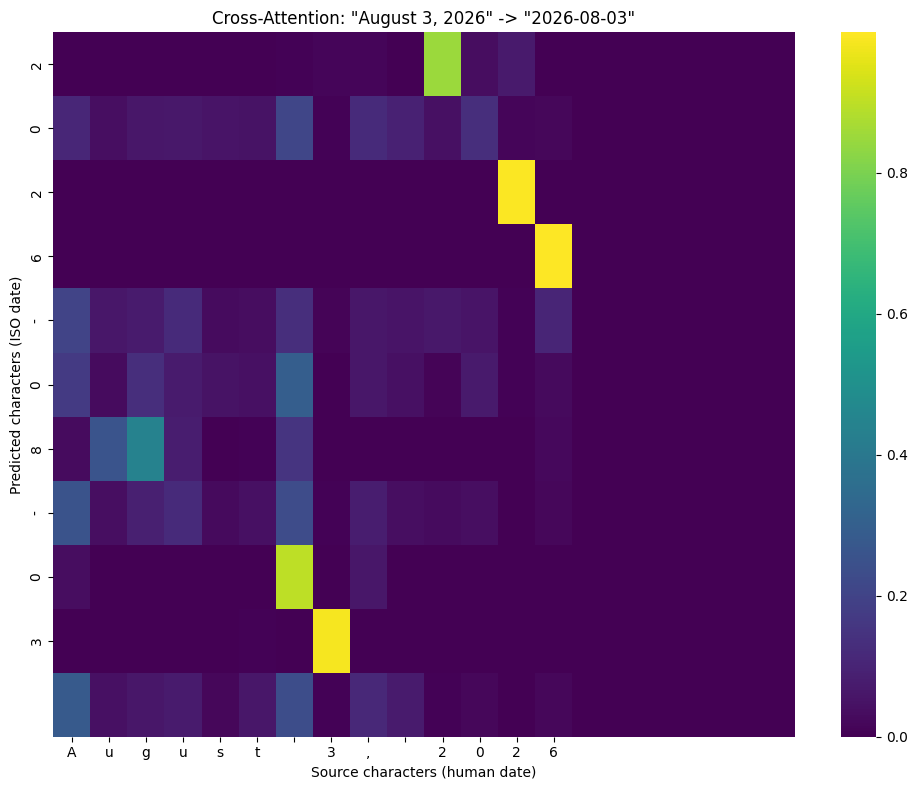

In [11]:
def translate_date_with_attention(human_date: str):
    """Same greedy decoding as `translate_date`, but also returns the
    cross-attention weights from the final decoder layer at every step.

    Returns:
        predicted_iso: The predicted ISO-format date string.
        cross_attn_matrix: Tensor of shape [1, tgt_len, src_len] with the
            final decoder layer's cross-attention weights for each
            generated character.
    """
    model.eval()
    with torch.no_grad():
        src = encode_str(human_date, max_len=20).unsqueeze(0).to(device)
        src_mask = model.create_padding_mask(src)

        memory = model.src_emb(src)
        for enc in model.encoder_layers:
            memory = enc(memory, src_key_padding_mask=src_mask)

        tgt_indices = [char2idx["<SOS>"]]
        attn_rows = []  # One [1, 1, src_len] row per generated character.

        for _ in range(15):
            tgt_tensor = torch.tensor([tgt_indices], device=device)
            tgt_mask = model.generate_square_subsequent_mask(tgt_tensor.size(1))

            out = model.tgt_emb(tgt_tensor)
            for dec in model.decoder_layers:
                out = dec(out, memory, tgt_mask=tgt_mask, memory_key_padding_mask=src_mask)

            # The final decoder layer's cross-attention weights, shape
            # [1, tgt_len_so_far, src_len]. We only need the row for the
            # token we are about to predict (the last position).
            last_layer_weights = model.decoder_layers[-1].last_cross_attn_weights
            attn_rows.append(last_layer_weights[:, -1:, :])

            logits = model.final_linear(out)
            next_token = logits[0, -1, :].argmax().item()

            if next_token == char2idx["<EOS>"]:
                break
            tgt_indices.append(next_token)

        predicted_iso = "".join([idx2char[idx] for idx in tgt_indices[1:]])
        cross_attn_matrix = torch.cat(attn_rows, dim=1)  # [1, tgt_len, src_len]

        return predicted_iso, cross_attn_matrix


def plot_attention_heatmap(human_date: str) -> None:
    """Translate a date and plot the cross-attention weights to physically
    see the Information Bridge between source characters and predicted
    output characters."""
    predicted_iso, cross_attn_matrix = translate_date_with_attention(human_date)

    # Drop the batch dimension -> [tgt_len, src_len].
    attn_weights = cross_attn_matrix.squeeze(0).cpu().numpy()

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        attn_weights,
        cmap="viridis",
        xticklabels=list(human_date),
        yticklabels=list(predicted_iso),
    )
    plt.xlabel("Source characters (human date)")
    plt.ylabel("Predicted characters (ISO date)")
    plt.title(f'Cross-Attention: "{human_date}" -> "{predicted_iso}"')
    plt.tight_layout()
    plt.show()


plot_attention_heatmap("August 3, 2026")
